<h1 align='center' style='color:purple'>Clustering With K Means - Python Tutorial</h1>

## 3. The K-Means algorithm and its objective function

### 3.1 Steps

1. **Choose K** – the number of clusters.
2. **Initialise** K centroids $\mu_1, \dots, \mu_K$ (randomly picked points, or the smarter *k-means++* in scikit-learn).
3. **Assignment step** – give each point $x_i$ to the closest centroid using **Euclidean distance**:
$$d(x, \mu) = \sqrt{(x_1-\mu_1)^2 + (x_2-\mu_2)^2 + \dots}$$
$$c_i = \arg\min_{k}\; d(x_i, \mu_k)$$
4. **Update step** – move every centroid to the **mean** of the points assigned to it:
$$\mu_k = \frac{1}{|C_k|}\sum_{x_i \in C_k} x_i$$
5. **Repeat** steps 3–4 until the assignments (or centroids) stop changing — this is **convergence**.

### 3.2 What K-Means is minimising

K-Means minimises the **Within-Cluster Sum of Squares (WCSS)**, which scikit-learn calls **`inertia_`**:

$$\text{WCSS} = \sum_{k=1}^{K}\;\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

* Each assignment step and each update step can only **decrease (or keep)** the WCSS ⇒ the algorithm is guaranteed to converge.
* But it converges to a **local** minimum, which depends on the starting centroids. That is why scikit-learn runs it several times (`n_init`) and keeps the best result.

## 4. Numerical worked example (by hand) ✍️

Let's cluster **7 points** into **K = 2** clusters completely by hand, and then let Python confirm every number.

| Point | x | y |
|---|---|---|
| A | 1.0 | 1.0 |
| B | 1.5 | 2.0 |
| C | 3.0 | 4.0 |
| D | 5.0 | 7.0 |
| E | 3.5 | 5.0 |
| F | 4.5 | 5.0 |
| G | 3.5 | 4.5 |

**Initial centroids** (chosen as two far-apart points): $\mu_1 = A = (1, 1)$ and $\mu_2 = D = (5, 7)$.

---

### 🔁 Iteration 1

**Assignment step.** Example calculation for point **B (1.5, 2)**:

$$d(B,\mu_1) = \sqrt{(1.5-1)^2 + (2-1)^2} = \sqrt{0.25+1} = \sqrt{1.25} = 1.118$$
$$d(B,\mu_2) = \sqrt{(1.5-5)^2 + (2-7)^2} = \sqrt{12.25+25} = \sqrt{37.25} = 6.103$$

$1.118 < 6.103$ ⇒ **B → Cluster 1**. Doing this for every point:

| Point | d to μ₁ (1, 1) | d to μ₂ (5, 7) | Assigned to |
|---|---|---|---|
| A | 0.000 | 7.211 | **C1** |
| B | 1.118 | 6.103 | **C1** |
| C | 3.606 | 3.606 | **C1** *(tie → first centroid)* |
| D | 7.211 | 0.000 | **C2** |
| E | 4.717 | 2.500 | **C2** |
| F | 5.315 | 2.062 | **C2** |
| G | 4.301 | 2.915 | **C2** |

> ⚠️ Point **C** is *exactly* the same distance from both centroids. By convention (and in NumPy's `argmin`) ties go to the **first** centroid.

**Update step.**

$$\mu_1 = \text{mean}(A,B,C) = \left(\tfrac{1+1.5+3}{3},\; \tfrac{1+2+4}{3}\right) = (1.833,\; 2.333)$$
$$\mu_2 = \text{mean}(D,E,F,G) = \left(\tfrac{5+3.5+4.5+3.5}{4},\; \tfrac{7+5+5+4.5}{4}\right) = (4.125,\; 5.375)$$

---

### 🔁 Iteration 2

| Point | d to μ₁ (1.833, 2.333) | d to μ₂ (4.125, 5.375) | Assigned to |
|---|---|---|---|
| A | 1.572 | 5.376 | C1 |
| B | 0.471 | 4.276 | C1 |
| C | 2.034 | **1.777** | **C2** ⬅ *changed!* |
| D | 5.640 | 1.846 | C2 |
| E | 3.145 | 0.729 | C2 |
| F | 3.771 | 0.530 | C2 |
| G | 2.734 | 1.075 | C2 |

Point **C** has moved to Cluster 2. **Update step:**

$$\mu_1 = \text{mean}(A,B) = (1.25,\; 1.5)$$
$$\mu_2 = \text{mean}(C,D,E,F,G) = \left(\tfrac{3+5+3.5+4.5+3.5}{5},\; \tfrac{4+7+5+5+4.5}{5}\right) = (3.9,\; 5.1)$$

---

### 🔁 Iteration 3

| Point | d to μ₁ (1.25, 1.5) | d to μ₂ (3.9, 5.1) | Assigned to |
|---|---|---|---|
| A | 0.559 | 5.022 | C1 |
| B | 0.559 | 3.920 | C1 |
| C | 3.052 | 1.421 | C2 |
| D | 6.657 | 2.195 | C2 |
| E | 4.161 | 0.412 | C2 |
| F | 4.776 | 0.608 | C2 |
| G | 3.750 | 0.721 | C2 |

No point changed cluster ⇒ the centroids stay at $(1.25, 1.5)$ and $(3.9, 5.1)$ ⇒ **converged ✅**

**Final clusters:** C1 = {A, B}, C2 = {C, D, E, F, G}

### 📉 WCSS at the end

$$\text{WCSS} = \underbrace{(0.25^2+0.5^2) + (0.25^2+0.5^2)}_{\text{C1: } A, B = 0.625} + \underbrace{(0.9^2+1.1^2) + (1.1^2+1.9^2) + (0.4^2+0.1^2) + (0.6^2+0.1^2) + (0.4^2+0.6^2)}_{\text{C2} = 7.9} = 8.525$$

WCSS went **33.25 → 11.23 → 8.525** across the iterations (computed with the centroids used in each assignment step) — it never increases.

Now let's check all of this with code 👇

## 5. Evaluation metrics for clustering 📏

Because clustering has **no ground-truth labels**, we can't use accuracy. Instead we use:

* **Internal metrics** – judge the clusters using only the data (compactness & separation).
* **External metrics** – compare to true labels, *only if* they happen to be available (e.g. for teaching datasets like Iris).

### 5.1 Internal metrics

| Metric | Formula / idea | Range | Better when | In sklearn |
|---|---|---|---|---|
| **WCSS / Inertia** | $\sum_k \sum_{x \in C_k}\lVert x-\mu_k\rVert^2$ — compactness | $[0, \infty)$ | **Lower** (but *always* falls as K grows) | `km.inertia_` |
| **Silhouette score** | $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$ averaged over all points | $[-1, 1]$ | **Higher** (≈1 great, ≈0 overlapping, <0 wrong cluster) | `silhouette_score` |


In the silhouette:
* $a(i)$ = average distance from point $i$ to the **other points in its own cluster** (how tight its cluster is),
* $b(i)$ = average distance from point $i$ to the points of the **nearest other cluster** (how far the neighbours are).

### 5.2 External metrics (need true labels)

| Metric | Range | Meaning |
|---|---|---|
| **Adjusted Rand Index (ARI)** | $[-1, 1]$ | 1 = perfect match with true labels, ≈0 = random labelling |
| **Normalized Mutual Information (NMI)** | $[0, 1]$ | 1 = clusters carry exactly the same information as the labels |

Both ignore the *names* of the clusters — cluster "0" vs "1" swapped still scores 1.0.

---

### ✍️ Hand calculation: silhouette of point A in the worked example

Final clusters: C1 = {A, B}, C2 = {C, D, E, F, G}.

**a(A)** – A's own cluster contains only B:
$$a(A) = d(A,B) = 1.118$$

**b(A)** – average distance from A to every point of C2:
$$b(A) = \frac{d(A,C)+d(A,D)+d(A,E)+d(A,F)+d(A,G)}{5} = \frac{3.606+7.211+4.717+5.315+4.301}{5} = \frac{25.150}{5} = 5.030$$

$$s(A) = \frac{5.030 - 1.118}{\max(1.118,\; 5.030)} = \frac{3.912}{5.030} = \mathbf{0.778}$$

A is **well inside** its cluster (close to 1). Let's verify, and compute all metrics for the worked example:

In [1]:
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
from sklearn.metrics import silhouette_score
import numpy as np
%matplotlib inline

In [2]:
pts = np.array([[1,1],[1.5,2],[3,4],[5,7],[3.5,5],[4.5,5],[3.5,4.5]])
names = list("ABCDEFG")
mu = np.array([[1,1],[5,7]], dtype=float)
for it in range(1, 10):
    d = np.linalg.norm(pts[:, None] - mu[None], axis=2)
    lab = d.argmin(axis=1)                       # ties -> first centroid
    wcss_it = sum(((pts[lab == j] - mu[j])**2).sum() for j in range(2))
    print(f"Iteration {it}: assign={{n: int(l) + 1 for n, l in zip(names, lab)}}  WCSS(with these centroids)={wcss_it:.3f}")
    new_mu = np.array([pts[lab == j].mean(axis=0) for j in range(2)])
    print("   new centroids:", new_mu.round(3).tolist())
    if np.allclose(new_mu, mu): print("   converged"); break
    mu = new_mu

print("\nFinal WCSS:", round(wcss_it, 3))
km_demo = KMeans(n_clusters=2, init=np.array([[1,1],[5,7]]), n_init=1).fit(pts)
print("sklearn inertia_:", round(km_demo.inertia_, 3), "| centroids:", km_demo.cluster_centers_.round(3).tolist())
print("Silhouette (mean):", round(silhouette_score(pts, lab), 3))

# silhouette of point A by hand
a = np.linalg.norm(pts[0] - pts[1]); b = np.linalg.norm(pts[0] - pts[2:], axis=1).mean()
print(f"s(A) = ({b:.3f} - {a:.3f}) / {max(a, b):.3f} = {(b - a) / max(a, b):.3f}")

Iteration 1: assign={n: int(l) + 1 for n, l in zip(names, lab)}  WCSS(with these centroids)=33.250
   new centroids: [[1.833, 2.333], [4.125, 5.375]]
Iteration 2: assign={n: int(l) + 1 for n, l in zip(names, lab)}  WCSS(with these centroids)=11.226
   new centroids: [[1.25, 1.5], [3.9, 5.1]]
Iteration 3: assign={n: int(l) + 1 for n, l in zip(names, lab)}  WCSS(with these centroids)=8.525
   new centroids: [[1.25, 1.5], [3.9, 5.1]]
   converged

Final WCSS: 8.525
sklearn inertia_: 8.525 | centroids: [[1.25, 1.5], [3.9, 5.1]]
Silhouette (mean): 0.645
s(A) = (5.030 - 1.118) / 5.030 = 0.778


# Load the data set

In [3]:
df = pd.read_csv('income.csv')
df.head()

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


# Plot the scater plot

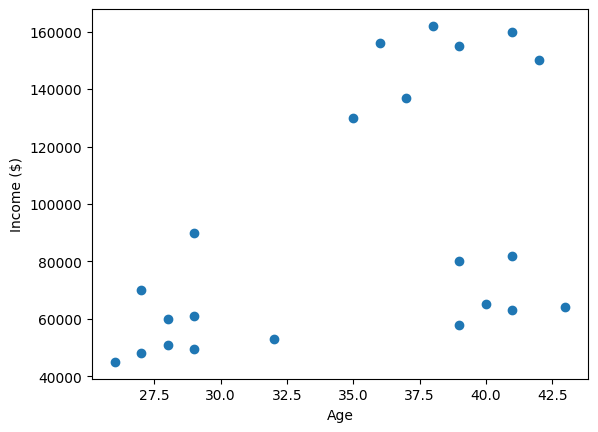

In [4]:
plt.scatter(df.Age, df['Income($)'])
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.show()

By eye there are clearly **3 groups**: young/low income (bottom-left), older/high income (top-right) and older/medium income (bottom-right).

# Bulid and Train the model

In [5]:
km = KMeans(n_clusters=3, n_init=10, random_state=0)
y_predicted = km.fit_predict(df[['Age', 'Income($)']])
y_predicted

array([2, 2, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0],
      dtype=int32)

# Assgin the cluster table to the samples 

In [6]:
df['cluster'] = y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,27,70000,2
1,Michael,29,90000,2
2,Mohan,29,61000,0
3,Ismail,28,60000,0
4,Kory,42,150000,1


In [7]:
km.cluster_centers_

array([[3.29090909e+01, 5.61363636e+04],
       [3.82857143e+01, 1.50000000e+05],
       [3.40000000e+01, 8.05000000e+04]])

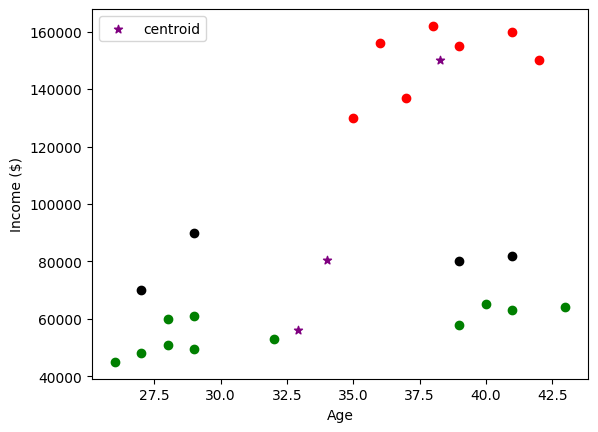

In [8]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.legend()

The clusters are cut **horizontally by income only** — some young people end up with older people. Why?

Because **Income ($) ranges over ~117,000 while Age ranges over only 17**. K-Means uses Euclidean distance, so the income difference swamps the age difference and Age barely influences the distances. The fix is to **put both features on the same scale**.

<h4 style='color:purple'>Preprocessing using min max scaler</h4>


**Min–Max scaling** squeezes every feature into the range $[0, 1]$:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

**Worked example** for Rob (Age 27, Income 70,000). Age range is 26 → 43, Income range is 45,000 → 162,000:

In [9]:
age_rob = (27 - 26) / (43 - 26)
inc_rob = (70000 - 45000) / (162000 - 45000)
print(round(age_rob, 4), round(inc_rob, 4))   # matches df.head() below: 0.0588, 0.2137

0.0588 0.2137


In [10]:
scaler = MinMaxScaler()

df[['Income($)', 'Age']] = scaler.fit_transform(
    df[['Income($)', 'Age']]
)

In [11]:
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,2
1,Michael,0.176471,0.384615,2
2,Mohan,0.176471,0.136752,0
3,Ismail,0.117647,0.128205,0
4,Kory,0.941176,0.897436,1


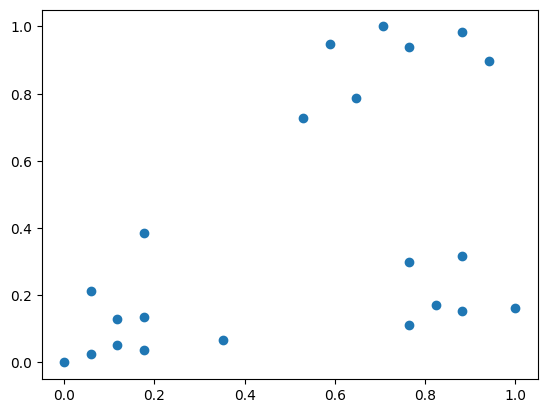

In [12]:
plt.scatter(df.Age,df['Income($)'])

In [13]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

array([1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0],
      dtype=int32)

In [14]:
df['cluster']=y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,2


In [15]:
km.cluster_centers_

array([[0.85294118, 0.2022792 ],
       [0.1372549 , 0.11633428],
       [0.72268908, 0.8974359 ]])

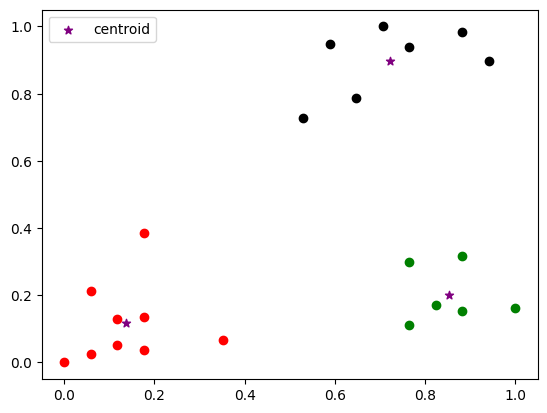

In [16]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.legend()

<h4 style='color:purple'>Elbow Plot</h4>

[![Picture1.png](https://i.postimg.cc/k5xhZXvY/Picture1.png)](https://postimg.cc/3yxB0h62)

# SSE and silhouette scores



---



In [17]:
k_range = range(2, 11)
sse = []
silhouette_scores = []
features = df[['Age', 'Income($)']]

for k in k_range:
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(features)
    sse.append(model.inertia_)
    silhouette_scores.append(silhouette_score(features, model.labels_))

for k, s, sc in zip(k_range, sse, silhouette_scores):
    print(f'k={k:2d}  SSE={s:.4f}  silhouette={sc:.4f}')

k= 2  SSE=2.0911  silhouette=0.5601
k= 3  SSE=0.4751  silhouette=0.7130
k= 4  SSE=0.3491  silhouette=0.6257
k= 5  SSE=0.2664  silhouette=0.5036
k= 6  SSE=0.2106  silhouette=0.4544
k= 7  SSE=0.1686  silhouette=0.4522
k= 8  SSE=0.1398  silhouette=0.4240
k= 9  SSE=0.1019  silhouette=0.3256
k=10  SSE=0.0851  silhouette=0.3230


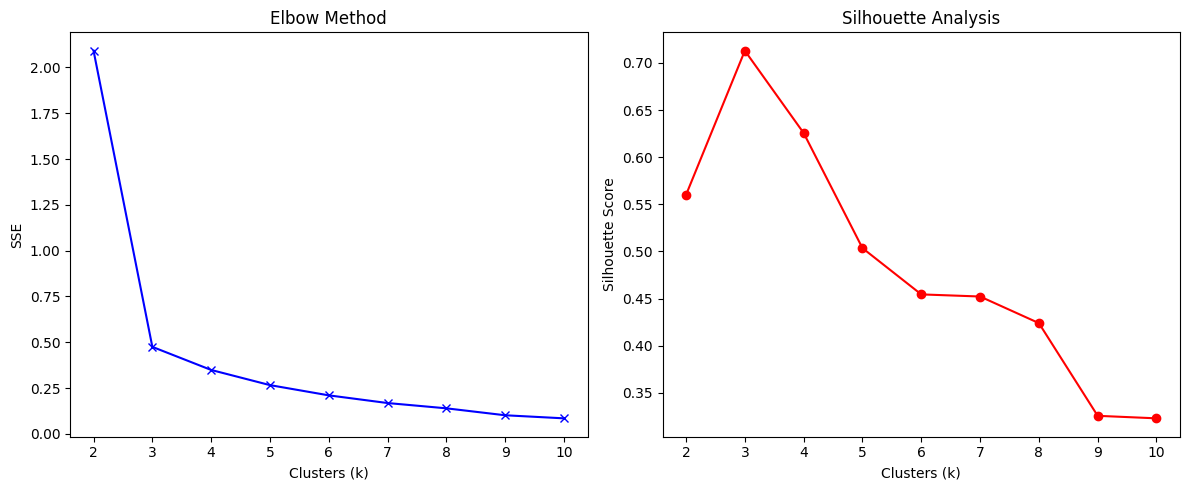

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(k_range, sse, 'bx-')
ax[0].set(title='Elbow Method', xlabel='Clusters (k)', ylabel='SSE')

ax[1].plot(k_range, silhouette_scores, 'ro-')
ax[1].set(title='Silhouette Analysis', xlabel='Clusters (k)', ylabel='Silhouette Score')

plt.tight_layout()
plt.show()

# load the dataset

In [19]:
df = pd.read_csv("income.csv")

print(df.head())

X = df[['Age', 'Income($)']].to_numpy(dtype=float)

      Name  Age  Income($)
0      Rob   27      70000
1  Michael   29      90000
2    Mohan   29      61000
3   Ismail   28      60000
4     Kory   42     150000


# Z-score normalization

In [20]:
# Z-score normalization
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print("Standardized Data:\n", X_scaled[:5])

Standardized Data:
 [[-1.35605536 -0.48068427]
 [-1.00915747 -0.01015907]
 [-1.00915747 -0.69242061]
 [-1.18260641 -0.71594687]
 [ 1.24567876  1.40141653]]


# Define the custom K-Means algorithm

In [21]:
def kmeans(X, k, max_iters=100, seed=42):
    """Plain NumPy K-Means. Returns (centroids, labels)."""
    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), size=k, replace=False)]      # random initial points
    for _ in range(max_iters):
        # assignment step: nearest centroid (Euclidean distance)
        dists = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        labels = dists.argmin(axis=1)
        # update step: mean of each cluster (keep old centroid if a cluster is empty)
        new_centroids = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j]
                                  for j in range(k)])
        if np.allclose(new_centroids, centroids):                  # convergence
            break
        centroids = new_centroids
    return centroids, labels

In [22]:
k = 3
centroids, labels = kmeans(X_scaled, k)

df['Cluster'] = labels

print(df.head())
print("Centroids:\n", centroids)

      Name  Age  Income($)  Cluster
0      Rob   27      70000        0
1  Michael   29      90000        0
2    Mohan   29      61000        0
3   Ismail   28      60000        0
4     Kory   42     150000        1
Centroids:
 [[-1.1247901  -0.74862223]
 [ 0.60143983  1.40141653]
 [ 0.98550535 -0.51205261]]


<h4 style='color:purple'>Exercise</h4>

## 📝 Lab Assignment: K-Means Clustering on the Wine Dataset — From Scratch vs. scikit-learn

### 🎯 Objective
Apply K-Means clustering to the **Wine dataset** in two ways:
1. a **from-scratch implementation**, written by you using only NumPy;
2. the **predefined `KMeans`** class from scikit-learn.

Evaluate both with standard clustering metrics and compare the results.

---

### 📂 Step 1 — Load the dataset
```python
from sklearn.datasets import load_wine
wine = load_wine()
X, y_true = wine.data, wine.target      # 178 wines, 13 chemical features, 3 cultivars
```
> ⚠️ **Do NOT use `y_true` for clustering.** Keep it aside and use it **only** for the external metrics (ARI, NMI) in Step 6.

---

### 🔍 Step 2 — Explore and preprocess
- Put `X` into a DataFrame with `wine.feature_names`. Show its shape, `head()` and `describe()`.
- Look at the feature ranges: for example, *proline* goes up to ~1680, while *hue* is around 1.
- Apply `StandardScaler`. **Explain in a markdown cell why scaling is necessary** for K-Means here.
- Use **PCA** to get 2 components (`PCA(n_components=2)`), **for plotting only**. Cluster on all 13 scaled features.

---

### 🛠️ Step 3 — K-Means from scratch
Write a function `kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42)` using **only NumPy**. It must:
1. **Initialise** K centroids by picking random data points.
2. **Assign** each point to its nearest centroid using Euclidean distance.
3. **Update** each centroid to the mean of the points assigned to it.
4. **Stop** when the centroids no longer move (or `max_iters` is reached).
5. Repeat the whole run `n_init` times and keep the run with the **lowest WCSS**.
6. **Return** `centroids`, `labels`, `wcss` and the number of iterations.

Also write your own function to compute **WCSS**:
$$\text{WCSS} = \sum_{k=1}^{K}\sum_{x_i \in C_k}\lVert x_i-\mu_k\rVert^2$$

⭐ **Bonus:** implement the **silhouette score from scratch** and check that it matches `sklearn.metrics.silhouette_score`.

---

### 📦 Step 4 — K-Means with scikit-learn
```python
from sklearn.cluster import KMeans
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
```
Report `km.cluster_centers_`, `km.inertia_` and `km.n_iter_`.

---

### 📈 Step 5 — Choose the optimal K
For **K = 2 to 10**, using **both** implementations:
- Plot the **Elbow curve** (WCSS vs K).
- Plot the **Silhouette score vs K**.
- State your chosen K and explain why. Does it match the 3 true cultivars?

---

### 📏 Step 6 — Evaluate both models
Fill in this table for your chosen K:

| Metric | Type | Better | Scratch | scikit-learn |
|---|---|---|---|---|
| WCSS / Inertia | Internal | ↓ Lower | | |
| Silhouette score | Internal | ↑ Higher (max 1) | | |

---
## ✅ Solution — Wine dataset

### Step 1 — Load the dataset

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

wine = load_wine()
X, y_true = wine.data, wine.target      # y_true is kept aside: used ONLY for ARI / NMI
print(X.shape, np.bincount(y_true))

(178, 13) [59 71 48]


### Step 2 — Explore and preprocess

In [24]:
wine_df = pd.DataFrame(X, columns=wine.feature_names)
print("Shape:", wine_df.shape)
display(wine_df.head())
display(wine_df.describe().T)
print((wine_df.max() - wine_df.min()).sort_values(ascending=False).head(5).round(2))

Shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


proline              1402.00
magnesium              92.00
alcalinity_of_ash      19.40
color_intensity        11.72
malic_acid              5.06
dtype: float64


**Why scaling is necessary.** K-Means is built on Euclidean distance, so a feature with a large numeric range dominates the distance. In the Wine data, *proline* spans roughly 278–1680 and *magnesium* roughly 70–162, while *hue* is about 0.5–1.7 and *nonflavanoid phenols* about 0.1–0.7. Without scaling, the clusters would be decided almost entirely by proline (and a bit by magnesium), and the other 11 chemical measurements would be ignored — exactly the problem we saw with Income vs Age. `StandardScaler` rescales every feature to mean 0 and standard deviation 1 so that each one contributes comparably.

In [25]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("means ~0:", X_scaled.mean(axis=0).round(2)[:5], " stds ~1:", X_scaled.std(axis=0).round(2)[:5])

pca = PCA(n_components=2)                     # for PLOTTING only; clustering uses all 13 scaled features
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by 2 PCs:", pca.explained_variance_ratio_.round(3), "->", pca.explained_variance_ratio_.sum().round(3))

means ~0: [ 0.  0. -0. -0. -0.]  stds ~1: [1. 1. 1. 1. 1.]
Variance explained by 2 PCs: [0.362 0.192] -> 0.554


### Step 3 — K-Means from scratch (NumPy only)

In [26]:
def compute_wcss(X, centroids, labels):
    """WCSS = sum over clusters of squared distances of points to their centroid."""
    return float(sum(((X[labels == j] - centroids[j]) ** 2).sum() for j in range(len(centroids))))


def kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        # 1. initialise: K random data points
        centroids = X[rng.choice(len(X), size=k, replace=False)].copy()
        for it in range(1, max_iters + 1):
            # 2. assign: nearest centroid by Euclidean distance
            dists = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
            labels = dists.argmin(axis=1)
            # 3. update: mean of each cluster (re-seed a cluster that became empty)
            new_centroids = centroids.copy()
            for j in range(k):
                members = X[labels == j]
                new_centroids[j] = members.mean(axis=0) if len(members) else X[rng.integers(len(X))]
            # 4. stop when centroids no longer move
            moved = np.linalg.norm(new_centroids - centroids)
            centroids = new_centroids
            if moved < 1e-8:
                break
        # final consistent assignment for the converged centroids
        labels = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2).argmin(axis=1)
        wcss = compute_wcss(X, centroids, labels)
        # 5. keep the run with the lowest WCSS
        if best is None or wcss < best[2]:
            best = (centroids, labels, wcss, it)
    return best      # 6. centroids, labels, wcss, n_iter


def silhouette_scratch(X, labels):
    """Mean silhouette score using only NumPy."""
    n = len(X)
    D = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
    uniq = np.unique(labels)
    s = np.zeros(n)
    for i in range(n):
        own = labels == labels[i]
        if own.sum() == 1:
            s[i] = 0.0; continue                                  # singleton cluster convention
        a = D[i, own].sum() / (own.sum() - 1)                     # exclude the point itself
        b = min(D[i, labels == c].mean() for c in uniq if c != labels[i])
        s[i] = (b - a) / max(a, b)
    return s.mean()


# quick test with k = 3
cent_s, lab_s, wcss_s, iters_s = kmeans_scratch(X_scaled, 3)
print("scratch  -> WCSS:", round(wcss_s, 4), "| iterations (best run):", iters_s)
print("silhouette scratch :", round(silhouette_scratch(X_scaled, lab_s), 6))
print("silhouette sklearn :", round(silhouette_score(X_scaled, lab_s), 6))
assert np.isclose(silhouette_scratch(X_scaled, lab_s), silhouette_score(X_scaled, lab_s))
print("Bonus check passed: the scratch silhouette matches scikit-learn.")

scratch  -> WCSS: 1277.9285 | iterations (best run): 3
silhouette scratch : 0.284859
silhouette sklearn : 0.284859
Bonus check passed: the scratch silhouette matches scikit-learn.


### Step 4 — K-Means with scikit-learn

In [27]:
k = 3
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
print("inertia_ :", round(km.inertia_, 4))
print("n_iter_  :", km.n_iter_)
print("cluster_centers_ (scaled space):")
print(pd.DataFrame(km.cluster_centers_, columns=wine.feature_names).round(3).T)

inertia_ : 1277.9285
n_iter_  : 7
cluster_centers_ (scaled space):
                                  0      1      2
alcohol                      -0.926  0.165  0.835
malic_acid                   -0.394  0.872 -0.304
ash                          -0.495  0.187  0.365
alcalinity_of_ash             0.171  0.524 -0.610
magnesium                    -0.492 -0.075  0.578
total_phenols                -0.076 -0.979  0.885
flavanoids                    0.021 -1.215  0.978
nonflavanoid_phenols         -0.034  0.726 -0.562
proanthocyanins               0.058 -0.780  0.580
color_intensity              -0.902  0.942  0.171
hue                           0.462 -1.165  0.474
od280/od315_of_diluted_wines  0.271 -1.292  0.779
proline                      -0.754 -0.407  1.125


### Step 5 — Choose the optimal K (K = 2 … 10, both implementations)

,wcss_scratch,sil_scratch,wcss_sk,sil_sk
K,,,,
2,1659.0080,0.2683,1658.7589,0.2593
3,1277.9285,0.2849,1277.9285,0.2849
4,1180.0526,0.2522,1175.4283,0.2602
5,1105.5186,0.2360,1109.5127,0.2016
6,1057.4994,0.2051,1046.0023,0.2372
7,982.8941,0.1963,981.5952,0.2036
8,964.4976,0.1306,935.2012,0.1570
9,900.4016,0.1583,889.8929,0.1499
10,874.1875,0.1375,845.8952,0.1436


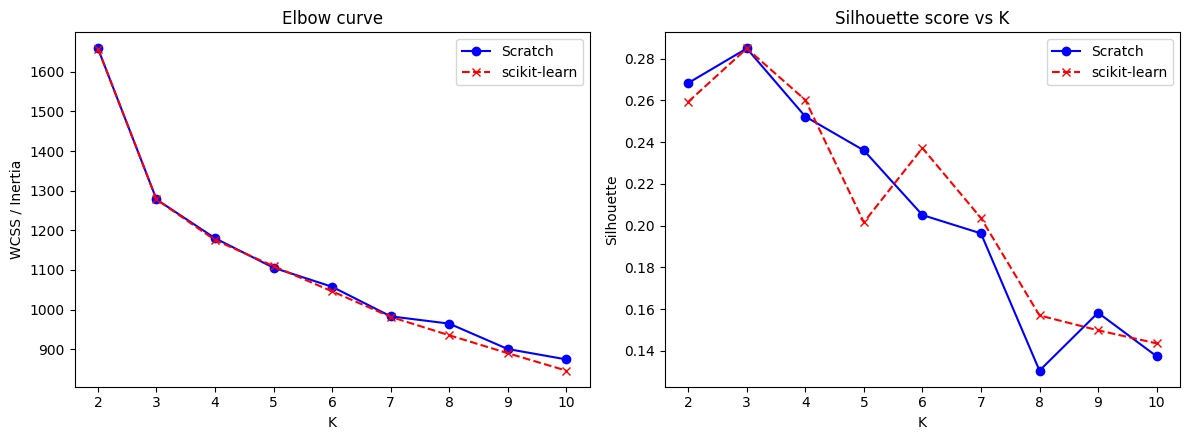

K with highest silhouette (sklearn): 3


In [28]:
ks = range(2, 11)
res = {"wcss_scratch": [], "sil_scratch": [], "wcss_sk": [], "sil_sk": []}
for kk in ks:
    c, l, w, _ = kmeans_scratch(X_scaled, kk)
    res["wcss_scratch"].append(w);  res["sil_scratch"].append(silhouette_scratch(X_scaled, l))
    m = KMeans(n_clusters=kk, n_init=10, random_state=42).fit(X_scaled)
    res["wcss_sk"].append(m.inertia_); res["sil_sk"].append(silhouette_score(X_scaled, m.labels_))

table = pd.DataFrame(res, index=list(ks)).round(4); table.index.name = "K"
display(table)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(list(ks), res["wcss_scratch"], "bo-", label="Scratch")
ax[0].plot(list(ks), res["wcss_sk"], "rx--", label="scikit-learn")
ax[0].set(title="Elbow curve", xlabel="K", ylabel="WCSS / Inertia"); ax[0].legend()
ax[1].plot(list(ks), res["sil_scratch"], "bo-", label="Scratch")
ax[1].plot(list(ks), res["sil_sk"], "rx--", label="scikit-learn")
ax[1].set(title="Silhouette score vs K", xlabel="K", ylabel="Silhouette"); ax[1].legend()
plt.tight_layout(); plt.show()
best_k = list(ks)[int(np.argmax(res["sil_sk"]))]
print("K with highest silhouette (sklearn):", best_k)

**Chosen K = 3.**

* **Silhouette:** both implementations peak at **K = 3** (0.285). K = 2 is lower (≈0.26–0.27) and every K ≥ 4 is lower still, so K = 3 gives the best-separated, most compact clusters.
* **Elbow:** the WCSS falls steeply from K = 2 → 3 (≈1659 → ≈1278) and then only gradually (≈100 per extra cluster), so the curve bends at **K = 3**.
* **True cultivars:** yes, this matches the **3 cultivars** in the data (59 / 71 / 48 wines). Note that the absolute silhouette (~0.28) is modest because the cultivars partly overlap in 13-dimensional space, and the curves are only a guide — the two methods agree here, which is reassuring.
* The scratch curve is very close to scikit-learn's. For some K (e.g. 2, 4, 8) the values differ slightly because the two use different initialisations (random points vs *k-means++*) and can land in different local minima; at K = 3 both reach exactly the same optimum.

### Step 6 — Evaluate both models (K = 3)

,Metric,Type,Better,Scratch,scikit-learn
0,WCSS / Inertia,Internal,↓ Lower,1277.9285,1277.9285
1,Silhouette score,Internal,↑ Higher (max 1),0.2849,0.2849
2,Adjusted Rand Index (ARI),External,↑ Higher (max 1),0.8975,0.8975
3,Normalized Mutual Info (NMI),External,↑ Higher (max 1),0.8759,0.8759


Agreement between the two clusterings (ARI): 1.0


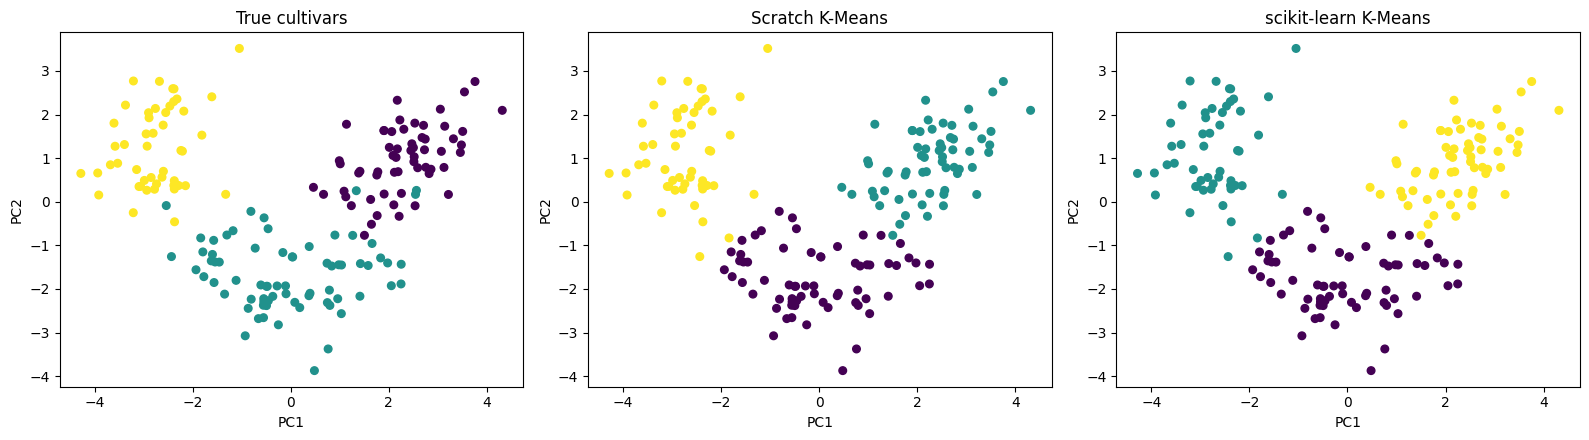

In [29]:
K = 3
cent_s, lab_s, wcss_s, iters_s = kmeans_scratch(X_scaled, K)
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
lab_k = km.labels_

rows = [
    ("WCSS / Inertia", "Internal", "↓ Lower",  wcss_s, km.inertia_),
    ("Silhouette score", "Internal", "↑ Higher (max 1)", silhouette_scratch(X_scaled, lab_s), silhouette_score(X_scaled, lab_k)),
    ("Adjusted Rand Index (ARI)", "External", "↑ Higher (max 1)", adjusted_rand_score(y_true, lab_s), adjusted_rand_score(y_true, lab_k)),
    ("Normalized Mutual Info (NMI)", "External", "↑ Higher (max 1)", normalized_mutual_info_score(y_true, lab_s), normalized_mutual_info_score(y_true, lab_k)),
]
results = pd.DataFrame(rows, columns=["Metric", "Type", "Better", "Scratch", "scikit-learn"])
results[["Scratch", "scikit-learn"]] = results[["Scratch", "scikit-learn"]].round(4)
display(results)
print("Agreement between the two clusterings (ARI):", round(adjusted_rand_score(lab_s, lab_k), 4))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, lab, t in zip(ax, [y_true, lab_s, lab_k], ["True cultivars", "Scratch K-Means", "scikit-learn K-Means"]):
    a.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap="viridis", s=30)
    a.set(title=t, xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()

### 🧾 Conclusions

| Metric | Type | Better | Scratch | scikit-learn |
|---|---|---|---|---|
| WCSS / Inertia | Internal | ↓ Lower | 1277.93 | 1277.93 |
| Silhouette score | Internal | ↑ Higher (max 1) | 0.2849 | 0.2849 |
| Adjusted Rand Index | External | ↑ Higher (max 1) | 0.8975 | 0.8975 |
| Normalized Mutual Information | External | ↑ Higher (max 1) | 0.8759 | 0.8759 |

* **The two implementations are equivalent.** At K = 3 they reach the same WCSS and silhouette score, and the two labelings agree perfectly (ARI between them = 1.0). The small differences at other values of K come only from initialisation / local minima. The scratch silhouette also matches `sklearn.metrics.silhouette_score` exactly.
* **Clustering quality.** Although the clustering never saw the labels, it recovers the true cultivars well (ARI ≈ 0.90, NMI ≈ 0.88). The PCA plot shows the three groups clearly, with only a few wines near the boundaries mis-assigned.
* **Why the internal score is low but the external one is high.** The silhouette of ~0.28 reflects some overlap between cultivars in 13-D space, not a bad clustering; the external metrics confirm that the clusters line up with the real classes.
* **Preprocessing mattered.** Standardising the features stopped *proline* (range ≈ 1400) from dominating the distance, which is what lets all 13 chemical measurements contribute.
* **Differences in practice.** scikit-learn is faster and uses *k-means++* initialisation, which tends to give better starting points; the scratch version needs more runs (`n_init`) to be as reliable but is fully transparent.